# 114 · Asynchronous inference: keep moving while the next chunk is computed

In [1]:
import os, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import FlowPolicy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

class LatencyPolicy:
    """Simulates an inference latency of L control steps.
    sync : the robot holds still (zero motion, same gripper) for L steps while waiting for each new chunk.
    async: the robot keeps executing the current chunk; the new chunk, computed from an L-step-old observation,
           arrives L steps later and its first L actions (already in the past) are skipped."""

    def __init__(self, base, latency, mode, execute=8):
        self.base, self.L, self.mode, self.k = base, latency, mode, execute

    def reset(self):
        self.queue, self.pending, self.wait, self.grip = [], None, 0, 0.0

    def _chunk(self, obs):
        return list(self.base._chunk(obs))

    def act(self, obs):
        if self.mode == "sync":
            if not self.queue:
                if self.wait < self.L:
                    self.wait += 1
                    return np.r_[np.zeros(6), self.grip]
                self.wait, self.queue = 0, self._chunk(obs)[: self.k]
        else:
            if self.pending is not None:
                self.pending[1] -= 1
                if self.pending[1] <= 0:
                    self.queue, self.pending = self.pending[0], None
            if len(self.queue) <= self.L and self.pending is None:
                chunk = self._chunk(obs)
                if not self.queue:
                    self.queue = chunk[: self.k] if self.L == 0 else [None] * self.L + chunk[self.L: self.L + self.k]   # None = hold while thinking
                else:
                    self.pending = [chunk[self.L: self.L + self.k], self.L]
            if not self.queue:
                return np.r_[np.zeros(6), self.grip]
        a = self.queue.pop(0)
        if a is None:
            return np.r_[np.zeros(6), self.grip]
        a = self.base.ds.to_command(a, self.base.env)                   # chunk entries are target poses -> env command
        a[6] = float(a[6] > 0.5); self.grip = a[6]
        return a

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
from vlacourse import need; need("../S08_Generative_Action_Heads/checkpoints/flow.pt", "S08 notebook 81")
flow = FlowPolicy(horizon=H); flow.load_state_dict(torch.load("../S08_Generative_Action_Heads/checkpoints/flow.pt", map_location=device)); flow.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
base = ChunkPolicy(flow, ds, env, device, nfe=4)
rows = {"sync": [], "async": []}
for L in [0, 2, 4, 6]:
    for mode in rows:
        r = evaluate(env, LatencyPolicy(base, L, mode), n_episodes=30, seed=50_000)
        steps = np.mean([e["steps"] for e in r["episodes"] if e["success"]]) if r["success"] else np.nan
        rows[mode].append((r["success"], steps))
        print(f"latency {L} steps ({L * 100} ms)  {mode:5s}: success {r['success']:.2f}, mean steps for successful episodes {steps:.1f}")

latency 0 steps (0 ms)  sync : success 0.97, mean steps for successful episodes 40.9


latency 0 steps (0 ms)  async: success 0.97, mean steps for successful episodes 41.1


latency 2 steps (200 ms)  sync : success 0.83, mean steps for successful episodes 50.6


latency 2 steps (200 ms)  async: success 1.00, mean steps for successful episodes 41.9


latency 4 steps (400 ms)  sync : success 0.87, mean steps for successful episodes 61.3


latency 4 steps (400 ms)  async: success 0.80, mean steps for successful episodes 50.7


latency 6 steps (600 ms)  sync : success 0.80, mean steps for successful episodes 70.0


latency 6 steps (600 ms)  async: success 0.93, mean steps for successful episodes 44.6


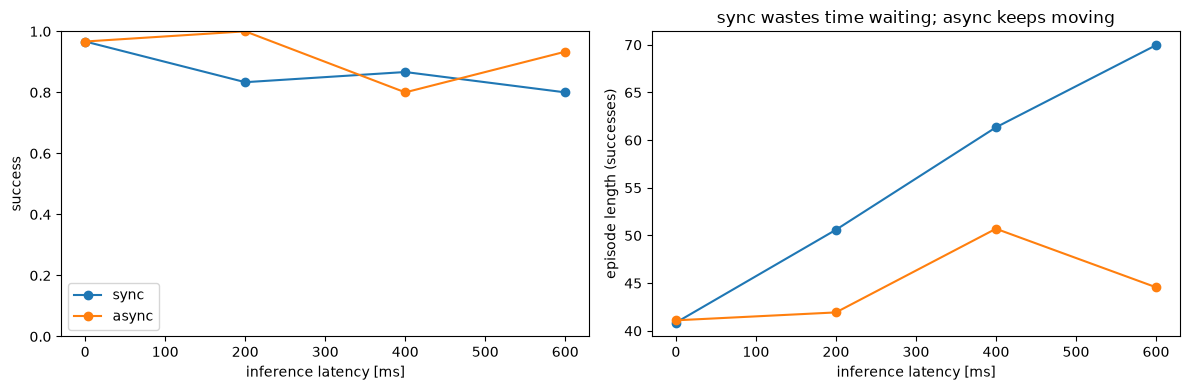

In [3]:
Ls = [0, 2, 4, 6]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for mode, v in rows.items():
    v = np.array(v); ax[0].plot(np.array(Ls) * 100, v[:, 0], "o-", label=mode); ax[1].plot(np.array(Ls) * 100, v[:, 1], "o-", label=mode)
ax[0].set_xlabel("inference latency [ms]"); ax[0].set_ylabel("success"); ax[0].set_ylim(0, 1); ax[0].legend()
ax[1].set_xlabel("inference latency [ms]"); ax[1].set_ylabel("episode length (successes)"); ax[1].set_title("sync wastes time waiting; async keeps moving"); plt.tight_layout(); plt.show()

### Watch it: 600 ms of inference latency
Synchronous inference freezes the robot while the network thinks; asynchronous inference keeps executing the previous chunk.

In [4]:
from vlacourse import showcase as sc
sc.compare(env, {"synchronous, 600 ms latency": LatencyPolicy(base, 6, "sync"), "asynchronous, 600 ms latency": LatencyPolicy(base, 6, "async")},
           seed=50_001, title="114 sync vs async inference")

114 sync vs async inference: synchronous, 600 ms latency: success | asynchronous, 600 ms latency: success


[True, True]